## EDA: Exploración

Análisis univariable y multivariable sobre `data/staging/`

### Constantes

- `MAX_PART`: máximo de oferentes de un proceso para contar pares que co-participan
- `MIN_OFERTAS`: ofertas mínimas de un proveedor para calcular su tasa de éxito
- `UMBRAL_HHI`: HHI desde el que una entidad se considera de alta concentración
- `MIN_PROCESOS`: procesos mínimos de un método para incluirlo en método × competencia

In [1]:
MAX_PART     = 30
MIN_OFERTAS  = 5
UMBRAL_HHI   = 0.25
MIN_PROCESOS = 500

### Utilidades

In [2]:
NOTEBOOK = "b_exploracion"
%run ../funciones.ipynb

In [3]:
spark = crear_spark(NOTEBOOK)
verificar_cluster(spark)

Master        : spark://spark-master:7077
Executors     : 2
Cores totales : 8
Memoria driver: 3.0 GB
UI del job    : http://localhost:4040


In [4]:
def barras(pdf, x, y, titulo, nombre, h=False, log=False, figsize=(8, 3)):
    ax = pdf.plot.barh(x=x, y=y, legend=False, figsize=figsize) if h else pdf.plot.bar(x=x, y=y, legend=False, figsize=figsize)
    if log:
        (ax.set_xscale if h else ax.set_yscale)("log")
    ax.set_title(titulo); ax.set_xlabel("" if not h else y); ax.set_ylabel("")
    mostrar_fig(nombre)

def ccdf(ax, conteos, titulo):
    d = conteos.sort_values("grado")
    p = d["count"][::-1].cumsum()[::-1] / d["count"].sum()
    ax.loglog(d["grado"].values, p.values, ".", ms=4)
    ax.set_title(titulo); ax.set_xlabel("grado"); ax.set_ylabel("P(G ≥ g)")

### Carga

In [5]:
proc  = leer(staging_dir, "procesos").where(F.col("anio").isin(anios)).cache()
adj   = leer(staging_dir, "adjudicaciones").where(F.col("anio").isin(anios) & F.col("proveedor_id_raw").isNotNull()).cache()
of    = leer(staging_dir, "oferentes").where(F.col("anio").isin(anios) & F.col("oferente_id_raw").isNotNull()).cache()
items = leer(staging_dir, "items").where(F.col("anio").isin(anios))
print(f"procesos {proc.count():,} | adjudicaciones {adj.count():,} | oferentes {of.count():,}")

procesos 235,984 | adjudicaciones 199,423 | oferentes 2,907,869


---
### **1. Análisis univariable**

#### a. Distribución temporal

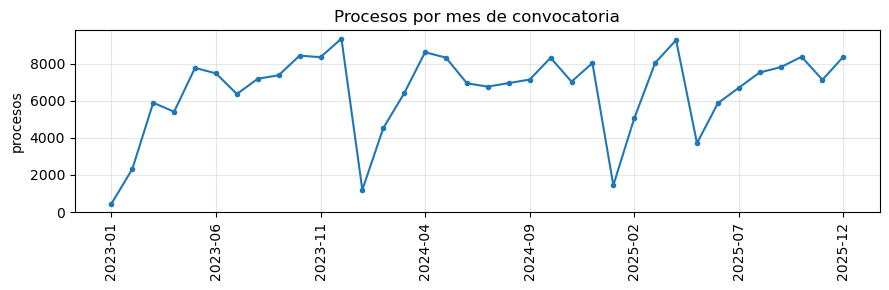

In [6]:
por_mes = proc.groupBy(F.date_format("fecha", "yyyy-MM").alias("mes")).count().orderBy("mes").toPandas()
por_mes.plot(x="mes", y="count", legend=False, figsize=(9, 3), marker=".", rot=90)
plt.title("Procesos por mes de convocatoria"); plt.xlabel(""); plt.ylabel("procesos")
mostrar_fig("procesos_por_mes")

- Mayoría de meses tiene entre ~5,000 y ~9,400 procesos, con un patrón anual estable

- **Enero es el mes más bajo** (440 / 1,198 / 1,445): el presupuesto del año recién se aprueba

- Diciembre está entre los más altos (cierre de ejecución)

- Sin huecos en 36 meses, así que se puede hacer **hold-out temporal** (entrenar 2023-2024, evaluar 2025)

#### b. Categoría y método

,categoria,count,pct
0,goods,105200,44.6
1,services,103656,43.9
2,works,27128,11.5


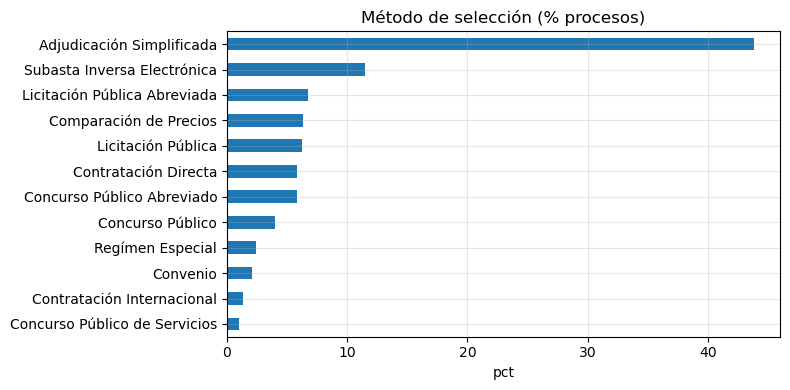

In [7]:
def distribucion(df, c, top=12):
    d = df.groupBy(c).count().orderBy(F.desc("count")).limit(top).toPandas()
    d["pct"] = (100 * d["count"] / df.count()).round(1)
    return d

dist_cat = distribucion(proc, "categoria")
dist_met = distribucion(proc, "metodo_detalle")
display(dist_cat)
barras(dist_met.iloc[::-1], "metodo_detalle", "pct", "Método de selección (% procesos)", "dist_metodo", h=True, figsize=(8, 4))

- **Bienes 44.6%, servicios 43.9%, obras 11.5%** de los procesos

- **Adjudicación simplificada** domina (43.8%), seguida de subasta inversa (11.5%); la **contratación directa es 5.8%**

- La categoría y el método entran como features de tipo y de competencia

#### c. Montos

In [8]:
monto_cat = (proc.where("monto_referencial > 0 AND moneda = 'PEN'").groupBy("categoria")
             .agg(F.count("*").alias("n"), F.expr("percentile_approx(monto_referencial, 0.5)").alias("mediana"),
                  F.expr("percentile_approx(monto_referencial, 0.99)").alias("p99"),
                  F.sum("monto_referencial").alias("total")).orderBy(F.desc("total")).toPandas())
monto_cat["pct_total"] = (100 * monto_cat.total / monto_cat.total.sum()).round(1)
monto_cat

,categoria,n,mediana,p99,total,pct_total
0,works,26682,1417715.58,1.335277e+08,2.122567e+11,57.3
1,services,94753,172142.60,1.298535e+07,9.982815e+10,27.0
2,goods,94228,151163.00,7.719203e+06,5.827384e+10,15.7


- **Las obras son el 11.5% de los procesos pero el 57.4% del monto** (mediana S/1.42M vs. ~S/150-170k en bienes y servicios)
- Por eso el monto se compara **dentro de cada categoría**, o con `log1p`

#### d. Competencia

postores p25/p50/p75/p90/p99: [3.0, 9.0, 17.0, 30.0, 72.0] | postor único: 12.3%


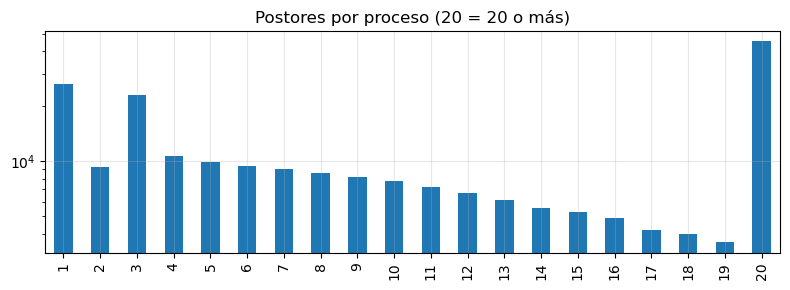

In [9]:
postores = proc.where("n_postores IS NOT NULL").select("n_postores")
q_post = postores.approxQuantile("n_postores", [.25, .5, .75, .9, .99], .001)
pct_unico = postores.select(F.avg((F.col("n_postores") == 1).cast("int"))).first()[0]
print(f"postores p25/p50/p75/p90/p99: {q_post} | postor único: {pct_unico:.1%}")
h = postores.groupBy(F.least("n_postores", F.lit(20)).alias("n")).count().orderBy("n").toPandas()
barras(h, "n", "count", "Postores por proceso (20 = 20 o más)", "postores", log=True)

- **Mediana de 9 postores**, pero el **12.3% de procesos tiene postor único**

- Distribución asimétrica: muchos procesos con pocos postores y una cola de procesos masivos

#### e. Frecuencia de entidades y proveedores

In [10]:
procesos_ent = proc.groupBy("entidad_id_raw").count()
adj_prov = adj.groupBy("proveedor_id_raw").agg(F.count("*").alias("count"), F.sum("monto_adj").alias("monto"))

def top_share(df, k, c="count"):
    total = df.agg(F.sum(c)).first()[0]
    return df.orderBy(F.desc(c)).limit(k).agg(F.sum(c)).first()[0] / total

frecuencia = pd.DataFrame([
    ("entidades", procesos_ent.count(), procesos_ent.approxQuantile("count", [.5], .01)[0], top_share(procesos_ent, 10)),
    ("proveedores", adj_prov.count(), adj_prov.approxQuantile("count", [.5], .01)[0], top_share(adj_prov, 10))],
    columns=["actor", "n", "mediana_por_actor", "share_top10"])
frecuencia

,actor,n,mediana_por_actor,share_top10
0,entidades,2996,28.0,0.115245
1,proveedores,86032,1.0,0.022776


In [11]:
(proc.groupBy("entidad").count().orderBy(F.desc("count")).show(5, truncate=60))
(adj.groupBy("proveedor").agg(F.count("*").alias("adjudicaciones"), F.round(F.sum("monto_adj") / 1e6, 1).alias("monto_MM"))
    .orderBy(F.desc("adjudicaciones")).show(5, truncate=60))

+-------------------------------------------------+-----+
|                                          entidad|count|
+-------------------------------------------------+-----+
|                          SEGURO SOCIAL DE  SALUD| 5583|
|ORGANISMO DE EVALUACION Y FISCALIZACION AMBIENTAL| 3501|
|                                 EJERCITO PERUANO| 3257|
|           GOBIERNO REGIONAL DE PUNO SEDE CENTRAL| 2919|
|                          PETROLEOS DEL PERU S.A.| 2855|
+-------------------------------------------------+-----+
only showing top 5 rows



+------------------------------------------------------------+--------------+--------+
|                                                   proveedor|adjudicaciones|monto_MM|
+------------------------------------------------------------+--------------+--------+
|GRUPO SANTA FE SOCIEDAD ANONIMA CERRADA - GRUPO SANTA FE ...|          1704|   355.5|
|                                  DIAGNOSTICA PERUANA S.A.C.|           572|   408.4|
|                MAPFRE PERU COMPAÑIA DE SEGUROS Y REASEGUROS|           344|   420.2|
|                                   AMERICA MOVIL PERU S.A.C.|           334|   541.9|
|           TMI-TYC SOCIEDAD ANONIMA CERRADA - TMI-TYC S.A.C.|           325|    50.8|
+------------------------------------------------------------+--------------+--------+
only showing top 5 rows



- **2,996 entidades** (mediana 28 procesos) y **86,017 proveedores ganadores** (mediana **1** adjudicación)

- Top 10 de entidades concentra el 11.5% de los procesos (EsSalud, OEFA, Ejército, GR Puno, Petroperú)

- Top 10 de proveedores solo el 2.3% de las adjudicaciones; pocos actores grandes y muchísimos pequeños

#### f. Rubros (UNSPSC)

procesos con UNSPSC: 84.6% | familias 389 | segmentos 56 | familias por proceso p50/p90/p99: [1.0, 1.0, 29.0]


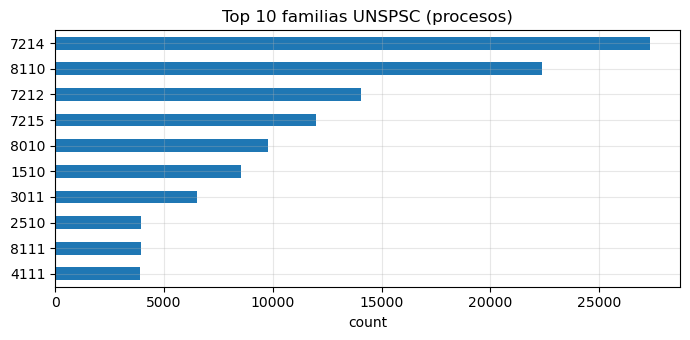

In [12]:
fam = items.where("unspsc IS NOT NULL").select("ocid", F.substring("unspsc", 1, 4).alias("familia"),
                                               F.substring("unspsc", 1, 2).alias("segmento")).distinct()
cobertura = fam.select("ocid").distinct().count() / proc.count()
n_fam, n_seg = fam.select("familia").distinct().count(), fam.select("segmento").distinct().count()
fam_por_proc = fam.groupBy("ocid").agg(F.countDistinct("familia").alias("n")).approxQuantile("n", [.5, .9, .99], .01)
print(f"procesos con UNSPSC: {cobertura:.1%} | familias {n_fam} | segmentos {n_seg} | familias por proceso p50/p90/p99: {fam_por_proc}")
top_fam = fam.groupBy("familia").count().orderBy(F.desc("count")).limit(10).toPandas()
barras(top_fam.iloc[::-1], "familia", "count", "Top 10 familias UNSPSC (procesos)", "top_familias", h=True, figsize=(7, 3.5))

- **84.6% de procesos con UNSPSC**; 389 familias en 56 segmentos

- Casi siempre **1 familia por proceso**, pero hay procesos con decenas (p99 = 29)

- Dominan construcción (7214, 7212, 7215), ingeniería (8110) y consultoría (8010)

- Seguidas de combustibles (1510), concreto (3011) y vehículos (2510)

---
### **2. Análisis multivariable**

#### a. Bipartito entidad–proveedor: densidad y grados

In [13]:
aristas = (adj.join(proc.select("ocid", "entidad_id_raw"), "ocid")
              .groupBy("entidad_id_raw", "proveedor_id_raw")
              .agg(F.count("*").alias("n_adj"), F.sum("monto_adj").alias("monto"))).cache()
n_e = aristas.select("entidad_id_raw").distinct().count()
n_p = aristas.select("proveedor_id_raw").distinct().count()
n_a = aristas.count()
grado_e = aristas.groupBy("entidad_id_raw").agg(F.count("*").alias("grado"))
grado_p = aristas.groupBy("proveedor_id_raw").agg(F.count("*").alias("grado"))
pct_p_grado1 = grado_p.where("grado = 1").count() / n_p
print(f"entidades {n_e:,} | proveedores {n_p:,} | aristas {n_a:,} | densidad {n_a / (n_e * n_p):.4%} | "
      f"proveedores con 1 entidad {pct_p_grado1:.1%}")

entidades 2,992 | proveedores 86,032 | aristas 136,124 | densidad 0.0529% | proveedores con 1 entidad 84.9%


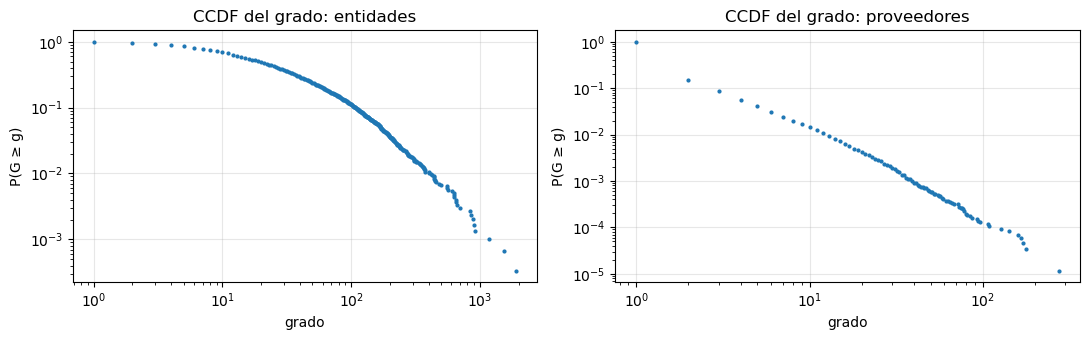

In [14]:
dist_grado = {"entidades": grado_e.groupBy("grado").count().toPandas(),
              "proveedores": grado_p.groupBy("grado").count().toPandas()}
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for i, (k, d) in enumerate(dist_grado.items()):
    ccdf(ax[i], d, f"CCDF del grado: {k}")
mostrar_fig("grado_ccdf")

- **2,992 entidades × 86,017 proveedores, 136,099 aristas: densidad 0.053%**; matriz extremadamente dispersa

- **84.9% de proveedores trabaja con una sola entidad:** son hojas del grafo

- **CCDF** = P(G ≥ g): proporción de actores con **g o más** conexiones

- La CCDF es casi recta en log-log (**cola pesada**): pocos actores concentran las conexiones

#### b. Método × competencia

In [15]:
met_comp = (proc.where("n_postores IS NOT NULL").groupBy("metodo_detalle")
            .agg(F.count("*").alias("procesos"), F.round(100 * F.avg((F.col("n_postores") == 1).cast("int")), 1).alias("pct_postor_unico"),
                 F.expr("percentile_approx(n_postores, 0.5)").alias("postores_mediana"))
            .where(f"procesos >= {MIN_PROCESOS}").orderBy(F.desc("pct_postor_unico")).toPandas())
met_comp

,metodo_detalle,procesos,pct_postor_unico,postores_mediana
0,Contratación Internacional,3104,98.1,1
1,Adjudicación Abreviada,1103,94.7,1
2,Contratación Directa,13412,88.7,1
3,Regímen Especial,5421,82.2,1
4,Convenio,4525,59.8,1
5,Adjudicación Selectiva,1539,19.4,3
6,Adjudicación Simplificada-Homologación,791,5.2,11
7,Subasta Inversa Electrónica,25133,2.3,7
8,Adjudicación Simplificada,91211,1.7,12
9,Licitación Pública Abreviada,14972,1.5,11


- Contratación internacional (98.1%) y adjudicación abreviada (94.7%)

- Contratación directa (88.7%) y régimen especial (82.2%)** son casi siempre de postor único

- Los métodos competitivos (licitación, concurso, subasta) están **bajo 2.5%**

- El método explica gran parte de la competencia: `pct_directa` y `pct_postor_unico` van como features

#### c. Oferentes por proceso y grafo de co-participación

In [16]:
n_of = of.groupBy("ocid").agg(F.countDistinct("oferente_id_raw").alias("n")).cache()
q_of = n_of.approxQuantile("n", [.5, .9, .99, .999], .001)
par = F.col("n") * (F.col("n") - 1) / 2
costo_pares = n_of.select(F.sum(par).alias("todos"),
                          *[F.sum(F.when(F.col("n") <= c, par)).alias(f"hasta_{c}") for c in (10, 30, 50)]).toPandas()
print(f"oferentes por proceso p50/p90/p99/p99.9: {q_of} | procesos con oferentes: {n_of.count():,} de {proc.count():,}")
costo_pares

oferentes por proceso p50/p90/p99/p99.9: [9.0, 31.0, 73.0, 341.0] | procesos con oferentes: 214,858 de 235,984


,todos,hasta_10,hasta_30,hasta_50
0,44285343.0,1438410.0,13097270.0,24211614.0


- **Mediana de 9 oferentes por proceso**, pero p99 = 75 y p99.9 = 341

- Un proceso con n oferentes genera n(n−1)/2 pares: sin tope serían **44.2M pares**

- Con tope en 30 (≈ p90) quedan 13.1M: se conserva el 90% de los procesos con un 30% de los pares

- Competir en un proceso de 40 postores dice menos que competir en uno de 3

#### d. Tasa de éxito

In [17]:
part = of.select("ocid", F.col("oferente_id_raw").alias("id")).distinct().withColumn("oferto", F.lit(1))
gana = adj.select("ocid", F.col("proveedor_id_raw").alias("id")).distinct().withColumn("gano", F.lit(1))
exito = part.join(gana, ["ocid", "id"], "full").fillna(0, ["oferto", "gano"])
resumen_exito = exito.agg(F.sum("oferto").alias("participaciones"),
                          F.sum(F.col("oferto") * F.col("gano")).alias("ganadas_listadas"),
                          F.sum(((F.col("oferto") == 0) & (F.col("gano") == 1)).cast("int")).alias("ganadas_no_listadas")).toPandas()
tasa = (exito.groupBy("id").agg(F.sum("oferto").alias("ofertas"), F.sum(F.col("oferto") * F.col("gano")).alias("ganadas"))
        .where(f"ofertas >= {MIN_OFERTAS}").withColumn("t", F.col("ganadas") / F.col("ofertas")))
q_tasa = tasa.approxQuantile("t", [.25, .5, .75, .9], .01)
print(f"tasa de éxito (≥ 5 ofertas) p25/p50/p75/p90: {q_tasa} | nunca ganan: {tasa.where('ganadas = 0').count() / tasa.count():.1%}")
resumen_exito

tasa de éxito (≥ 5 ofertas) p25/p50/p75/p90: [0.0, 0.0, 0.10526315789473684, 0.25] | nunca ganan: 50.4%


,participaciones,ganadas_listadas,ganadas_no_listadas
0,2907869,199247,23


- 2.9M participaciones y 199k ganadas: **tasa de éxito mediana 0** entre quienes ofertan ≥ 5 veces

- **50.4% de esos proveedores nunca gana:** `tasa_exito` y `compite` son features informativas

- Solo 23 ganadores no aparecen como oferentes

#### e. Multi-pertenencia: región y rubro

In [18]:
seg = fam.select("ocid", "segmento").distinct()
mp = (adj.select("ocid", "proveedor_id_raw").distinct()
         .join(proc.select("ocid", "region"), "ocid").join(seg, "ocid", "left")
         .groupBy("proveedor_id_raw").agg(F.countDistinct("region").alias("n_regiones"),
                                          F.countDistinct("segmento").alias("n_segmentos")))
multi = mp.agg(F.round(100 * F.avg((F.col("n_regiones") > 1).cast("int")), 1).alias("pct_multi_region"),
               F.round(100 * F.avg((F.col("n_segmentos") > 1).cast("int")), 1).alias("pct_multi_segmento")).toPandas()
multi

,pct_multi_region,pct_multi_segmento
0,11.0,9.9


- **10.9% de proveedores gana en varias regiones y 9.9% en varios segmentos:** 

- La mayoría vive en un solo mercado

- Hay una minoría multi-mercado suficiente para justificar comunidades **solapadas**

#### f. Concentración por entidad (HHI)

HHI p25/p50/p75/p90: [0.079, 0.168, 0.339, 0.567] | entidades con HHI > 0.25: 36.8%


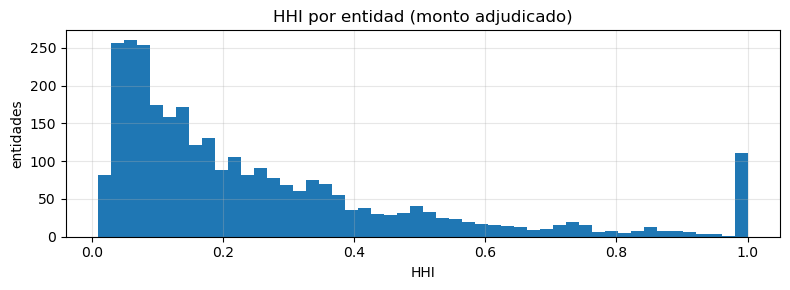

In [19]:
w = Window.partitionBy("entidad_id_raw")
hhi = (aristas.where("monto > 0").withColumn("s", F.col("monto") / F.sum("monto").over(w))
       .groupBy("entidad_id_raw").agg(F.sum(F.col("s") ** 2).alias("hhi"), F.max("s").alias("share_top"))).cache()
q_hhi = hhi.approxQuantile("hhi", [.25, .5, .75, .9], .01)
pct_hhi_alto = hhi.where(f"hhi > {UMBRAL_HHI}").count() / hhi.count()
print(f"HHI p25/p50/p75/p90: {[round(x, 3) for x in q_hhi]} | entidades con HHI > {UMBRAL_HHI}: {pct_hhi_alto:.1%}")
plt.figure(figsize=(8, 3)); plt.hist(hhi.select("hhi").toPandas().hhi, bins=50)
plt.title("HHI por entidad (monto adjudicado)"); plt.xlabel("HHI"); plt.ylabel("entidades")
mostrar_fig("hhi_entidades")

- **HHI** = Σ (fracción del monto por proveedor)²

- 1 = un solo proveedor; cerca de 0 = gasto muy repartido

- **HHI mediano 0.17**, pero el **36.8% de las entidades tiene HHI > 0.25**

- Una de cada tres entidades depende fuertemente de pocos proveedores

#### g. Pares que co-participan seguido 

Procesos de 2 a 30 oferentes

In [20]:
of_cap = of.dropDuplicates(["ocid", "oferente_id_raw"]).join(n_of.where(f"n BETWEEN 2 AND {MAX_PART}").select("ocid"), "ocid")
top_pares = (of_cap.alias("a").join(of_cap.alias("b"),
                 (F.col("a.ocid") == F.col("b.ocid")) & (F.col("a.oferente_id_raw") < F.col("b.oferente_id_raw")))
             .groupBy(F.col("a.oferente_id_raw").alias("id_a"), F.col("b.oferente_id_raw").alias("id_b"))
             .agg(F.first("a.oferente").alias("oferente_a"), F.first("b.oferente").alias("oferente_b"),
                  F.count("*").alias("procesos_juntos"))
             .orderBy(F.desc("procesos_juntos")).limit(50).cache())
top_pares.select("oferente_a", "oferente_b", "procesos_juntos").show(8, truncate=40)

+----------------------------------------+----------------------------------------+---------------+
|                              oferente_a|                              oferente_b|procesos_juntos|
+----------------------------------------+----------------------------------------+---------------+
| J.C.A. CONTRATISTAS GENERALES S.R.LTDA.|TECNICAS DE INGENIERIA Y CONTRATOS S....|           2713|
|GRUPO 3A CONSULTORIA & CONSTRUCCIONES...|                     JATUN SACHA E.I.R.L|           2707|
|CORPORACION INTERNACIONAL RIO AMAZONA...|          CORPORACION GRUPO IBIZA S.A.C.|           2536|
| INVERSIONES GENERALES LAURA ROCA S.A.C.|                CONSTRUCAPRIGLE E.I.R.L.|           2430|
|TECNICAS DE INGENIERIA Y CONTRATOS S....|                 CRG INGENIEROS E.I.R.L.|           2404|
| INVERSIONES GENERALES LAURA ROCA S.A.C.|               TVT QONTRATISTAS E.I.R.L.|           2369|
|                JSG CONSTRUCTORES S.A.C.|                 CRG INGENIEROS E.I.R.L.|           2257|


- Hay pares de constructoras que se presentaron juntas a **más de 2,500 procesos** en tres años

- Son la materia prima de las comunidades: es una **señal descriptiva** de un mercado (mismo rubro o región)

---
### **3. Escritura de resultados**

In [21]:
escritos = guardar_tablas({
    "procesos_por_mes": por_mes, "dist_categoria": dist_cat, "dist_metodo": dist_met, "monto_categoria": monto_cat,
    "frecuencia_actores": frecuencia, "top_familias": top_fam, "metodo_competencia": met_comp,
    "resumen_bipartito": pd.DataFrame([{"entidades": n_e, "proveedores": n_p, "aristas": n_a,
                                        "densidad": n_a / (n_e * n_p), "pct_prov_grado1": pct_p_grado1}]),
    "grado_entidades": dist_grado["entidades"], "grado_proveedores": dist_grado["proveedores"],
    "oferentes_cuantiles": pd.DataFrame([dict(zip(["p50", "p90", "p99", "p999"], q_of))]),
    "costo_pares": costo_pares, "exito": resumen_exito, "multi_pertenencia": multi,
    "hhi_resumen": pd.DataFrame([dict(zip(["p25", "p50", "p75", "p90"], q_hhi), pct_hhi_alto=pct_hhi_alto)]),
    "top_pares_coparticipacion": top_pares})

Escrito en 00_EDA/temp/b_exploracion/: procesos_por_mes, dist_categoria, dist_metodo, monto_categoria, frecuencia_actores, top_familias, metodo_competencia, resumen_bipartito, grado_entidades, grado_proveedores, oferentes_cuantiles, costo_pares, exito, multi_pertenencia, hhi_resumen, top_pares_coparticipacion


#### a. Verificación

In [22]:
verificar_salidas(escritos)

OK: 16 tablas (parquet + json) | 6 figuras: dist_metodo, grado_ccdf, hhi_entidades, postores, procesos_por_mes, top_familias


---
### **4. Cerrar sesión**

In [23]:
spark.stop()